# 01 — Exploratory Data Analysis: PaySim Mobile Money Fraud Dataset

**Project:** Real-Time Fraud Detection & Risk Scoring Platform  
**Dataset:** [PaySim Synthetic Financial Datasets for Fraud Detection (Kaggle)](https://www.kaggle.com/datasets/ealaxi/paysim1)

### Prerequisite
Download `PS_20174392719_1491204439457_log.csv` from Kaggle and place it at:
`data/raw/PS_20174392719_1491204439457_log.csv`

### Important Dataset Limitations
- PaySim is a synthetic mobile-money simulation, **not** genuine production banking data.
- `step` represents 1-indexed hourly simulation ticks (1..743 = ~30 days).
- `amount` values are unitless simulator magnitudes and must **not** be assumed to be INR or USD.
- Post-transaction balance fields (`newbalanceOrig`, `newbalanceDest`) are excluded from serving features to prevent leakage.

## 1. Imports and Configuration

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.data.audit import audit_paysim_dataframe, validate_paysim_schema
from src.utils.config import get_config

sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.figsize'] = (10, 5)

cfg = get_config()
RAW_CSV = PROJECT_ROOT / cfg['paths']['raw_paysim_file']
PLOTS_DIR = PROJECT_ROOT / cfg['paths']['plots_dir']
PLOTS_DIR.mkdir(parents=True, exist_ok=True)
print('Expected PaySim path:', RAW_CSV)

Expected PaySim path: C:\Users\vinay\fraud-detection-platform\data\raw\PS_20174392719_1491204439457_log.csv


## 2. Dataset Loading

In [2]:
if not RAW_CSV.exists():
    raise FileNotFoundError(
        f'PaySim CSV not found at {RAW_CSV}. Download it from '
        'https://www.kaggle.com/datasets/ealaxi/paysim1 and place it in data/raw/.'
    )

df = pd.read_csv(RAW_CSV)
print(f'Loaded shape: {df.shape[0]:,} rows x {df.shape[1]} columns')

Loaded shape: 6,362,620 rows x 11 columns


## 3. Dataset Overview & 4. Schema Inspection

In [3]:
display(df.head())
schema_report = validate_paysim_schema(df, config=cfg)
print('Schema valid:', schema_report['is_valid'])
print('Errors:', schema_report['errors'])
display(pd.DataFrame({'dtype': df.dtypes.astype(str), 'nunique': df.nunique()}))

,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0
1,1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0
2,1,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1,0
3,1,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1,0
4,1,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0,0


Schema valid: True
Errors: []


,dtype,nunique
step,int64,743
type,object,5
amount,float64,5316900
nameOrig,object,6353307
oldbalanceOrg,float64,1845844
newbalanceOrig,float64,2682586
nameDest,object,2722362
oldbalanceDest,float64,3614697
newbalanceDest,float64,3555499
isFraud,int64,2


## 5. Missing-Value Analysis & 6. Duplicate Analysis

In [4]:
audit_report = audit_paysim_dataframe(df, config=cfg)
missing_df = pd.DataFrame({
    'missing_count': audit_report['missing_values']['counts'],
    'missing_pct': audit_report['missing_values']['percentages'],
})
display(missing_df)
print('Exact duplicate rows:', audit_report['duplicate_rows'])

,missing_count,missing_pct
step,0,0.0
type,0,0.0
amount,0,0.0
nameOrig,0,0.0
oldbalanceOrg,0,0.0
newbalanceOrig,0,0.0
nameDest,0,0.0
oldbalanceDest,0,0.0
newbalanceDest,0,0.0
isFraud,0,0.0


Exact duplicate rows: {'exact_duplicate_count': 0, 'exact_duplicate_pct': 0.0}


## 7. Fraud Distribution (Severe Class Imbalance)

Fraud count: 8,213 (0.1291%)
Legit count: 6,354,407
Imbalance ratio (legit:fraud): 773.7:1
isFlaggedFraud count: 16


C:\Users\vinay\AppData\Local\Temp\ipykernel_32852\2698507252.py:11: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(['Legitimate (0)', 'Fraud (1)'])


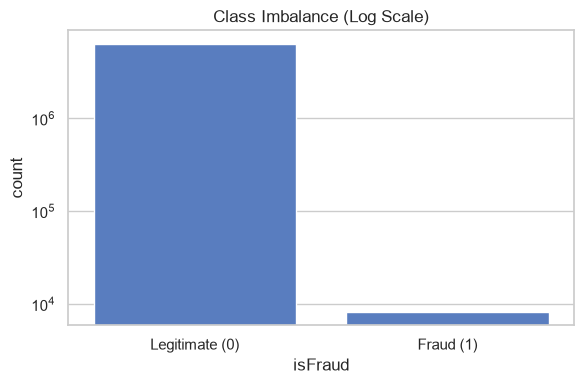

In [5]:
fraud_dist = audit_report['fraud_distribution']
print(f"Fraud count: {fraud_dist['fraud_count']:,} ({fraud_dist['fraud_rate']*100:.4f}%)")
print(f"Legit count: {fraud_dist['legitimate_count']:,}")
print(f"Imbalance ratio (legit:fraud): {fraud_dist['imbalance_ratio_legit_to_fraud']}:1")
print(f"isFlaggedFraud count: {fraud_dist['flagged_fraud_count']:,}")

fig, ax = plt.subplots(figsize=(6, 4))
sns.countplot(data=df, x='isFraud', ax=ax)
ax.set_yscale('log')
ax.set_title('Class Imbalance (Log Scale)')
ax.set_xticklabels(['Legitimate (0)', 'Fraud (1)'])
plt.tight_layout()
plt.savefig(PLOTS_DIR / 'eda_class_imbalance.png', dpi=150)
plt.show()

## 8. Transaction Type Analysis

,total_tx,fraud_tx,fraud_rate
type,,,
CASH_OUT,2237500,4116,0.001840
TRANSFER,532909,4097,0.007688
CASH_IN,1399284,0,0.000000
DEBIT,41432,0,0.000000
PAYMENT,2151495,0,0.000000


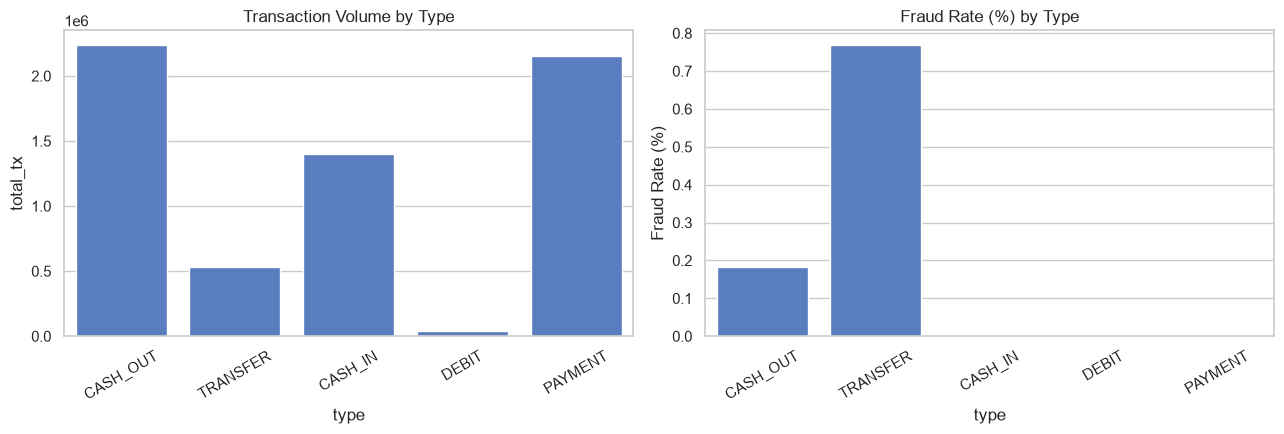

In [6]:
type_summary = df.groupby('type')['isFraud'].agg(['count', 'sum', 'mean']).rename(
    columns={'count': 'total_tx', 'sum': 'fraud_tx', 'mean': 'fraud_rate'}
).sort_values('fraud_tx', ascending=False)
display(type_summary)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.barplot(x=type_summary.index, y=type_summary['total_tx'], ax=axes[0])
axes[0].set_title('Transaction Volume by Type')
axes[0].tick_params(axis='x', rotation=30)

sns.barplot(x=type_summary.index, y=type_summary['fraud_rate'] * 100, ax=axes[1])
axes[1].set_title('Fraud Rate (%) by Type')
axes[1].set_ylabel('Fraud Rate (%)')
axes[1].tick_params(axis='x', rotation=30)
plt.tight_layout()
plt.savefig(PLOTS_DIR / 'eda_tx_type_fraud.png', dpi=150)
plt.show()

## 9. Transaction Amount Distribution (Unitless PaySim Scale)

,count,mean,std,min,25%,50%,75%,95%,99%,max
isFraud,,,,,,,,,,
0,6354407.0,1.781970e+05,5.962370e+05,0.01,13368.395,74684.72,208364.76,515610.423,1.586064e+06,92445516.64
1,8213.0,1.467967e+06,2.404253e+06,0.00,127091.330,441423.44,1517771.48,8006429.040,1.000000e+07,10000000.00


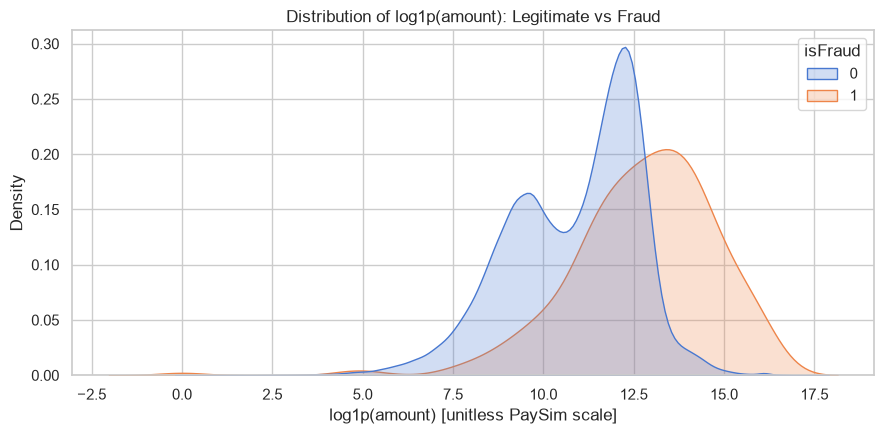

In [7]:
display(df.groupby('isFraud')['amount'].describe(percentiles=[0.25, 0.5, 0.75, 0.95, 0.99]))

sample_df = df.sample(n=min(200_000, len(df)), random_state=42).copy()
sample_df['log_amount'] = np.log1p(sample_df['amount'])

fig, ax = plt.subplots(figsize=(9, 4.5))
sns.kdeplot(data=sample_df, x='log_amount', hue='isFraud', common_norm=False, fill=True, ax=ax)
ax.set_title('Distribution of log1p(amount): Legitimate vs Fraud')
ax.set_xlabel('log1p(amount) [unitless PaySim scale]')
plt.tight_layout()
plt.savefig(PLOTS_DIR / 'eda_amount_distribution.png', dpi=150)
plt.show()

## 10. Temporal Analysis (`step` and Hour-of-Day Cycle)

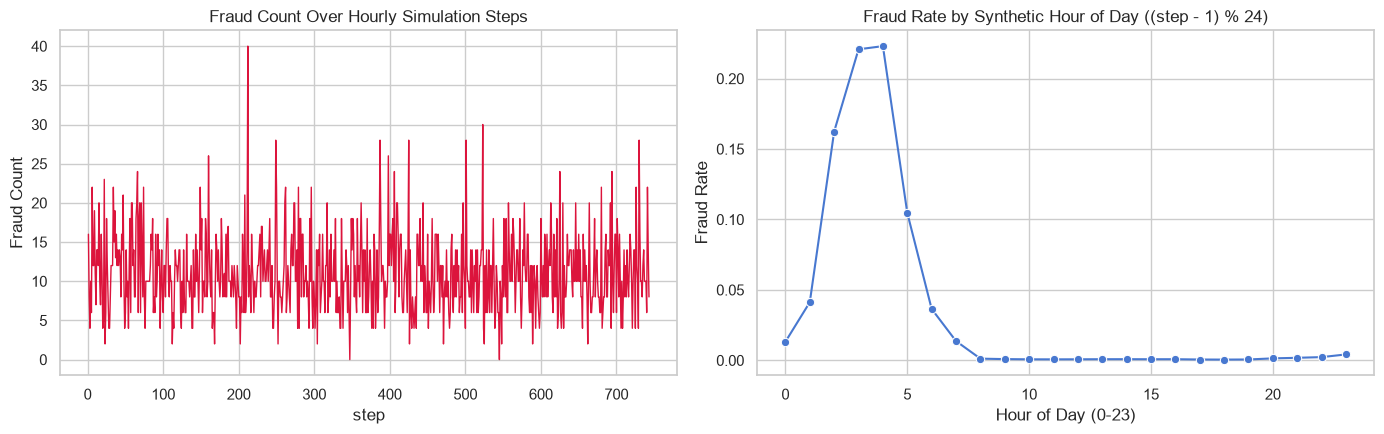

In [8]:
df['step_hour_of_day'] = (df['step'] - 1) % 24
step_agg = df.groupby('step').agg(total_tx=('isFraud', 'count'), fraud_tx=('isFraud', 'sum')).reset_index()
hour_agg = df.groupby('step_hour_of_day').agg(total_tx=('isFraud', 'count'), fraud_rate=('isFraud', 'mean')).reset_index()

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].plot(step_agg['step'], step_agg['fraud_tx'], color='crimson', lw=1)
axes[0].set_title('Fraud Count Over Hourly Simulation Steps')
axes[0].set_xlabel('step')
axes[0].set_ylabel('Fraud Count')

sns.lineplot(data=hour_agg, x='step_hour_of_day', y='fraud_rate', marker='o', ax=axes[1])
axes[1].set_title('Fraud Rate by Synthetic Hour of Day ((step - 1) % 24)')
axes[1].set_xlabel('Hour of Day (0-23)')
axes[1].set_ylabel('Fraud Rate')
plt.tight_layout()
plt.savefig(PLOTS_DIR / 'eda_temporal_analysis.png', dpi=150)
plt.show()

## 11. Account Behaviour Analysis (`nameOrig` Velocity & Repeat Activity)

In [9]:
orig_counts = df['nameOrig'].value_counts()
print('Unique originating accounts:', f'{len(orig_counts):,}')
print('Accounts with >1 transaction:', f'{(orig_counts > 1).sum():,} ({(orig_counts > 1).mean()*100:.3f}%)')
print('Max transactions per originating account:', int(orig_counts.max()))

same_step_dups = df.groupby(['nameOrig', 'step']).size()
print('Account-step pairs with >1 transaction (same-step risk):', int((same_step_dups > 1).sum()))

Unique originating accounts: 6,353,307
Accounts with >1 transaction: 9,298 (0.146%)
Max transactions per originating account: 3


Account-step pairs with >1 transaction (same-step risk): 47


## 12. Statistical Findings (Non-Parametric Hypothesis Tests)

In [10]:
fraud_amounts = df.loc[df['isFraud'] == 1, 'amount']
legit_amounts = df.loc[df['isFraud'] == 0, 'amount'].sample(n=min(100_000, (df['isFraud'] == 0).sum()), random_state=42)
u_stat, p_val = stats.mannwhitneyu(fraud_amounts, legit_amounts, alternative='two-sided')
print(f'Mann-Whitney U test (fraud vs legit amounts): U={u_stat:.2f}, p-value={p_val:.4e}')

ct = pd.crosstab(df['type'], df['isFraud'])
chi2, chi_p, dof, _ = stats.chi2_contingency(ct)
print(f'Chi-square test (tx_type vs isFraud): chi2={chi2:.2f}, dof={dof}, p-value={chi_p:.4e}')

Mann-Whitney U test (fraud vs legit amounts): U=648526407.50, p-value=0.0000e+00


Chi-square test (tx_type vs isFraud): chi2=22082.54, dof=4, p-value=0.0000e+00


## 13–15. Data Quality Conclusions & Implications for SQL Feature Engineering

1. **Severe Class Imbalance:** Accuracy is uninformative; we use **PR-AUC (Average Precision)** as the primary model selection metric and apply class weighting (`class_weight='balanced'`, `scale_pos_weight`) with Validation-only calibration.
2. **Transaction Type Concentration:** Fraud in PaySim concentrates heavily in `TRANSFER` and `CASH_OUT`, justifying both one-hot encoding of `tx_type` and the historical behavioural feature `high_risk_type_count_24_steps`.
3. **Heavy-Tailed Amounts:** Transaction amounts span orders of magnitude; including both raw `amount`, `log1p(amount)`, and relative account ratios (`amount_vs_user_avg_ratio`, `amount_vs_user_max_ratio`) captures anomalous spikes.
4. **Same-Step & Future Leakage Prevention:** Because multiple transactions can share the same `step` without sub-hour ordering, `sql/features.sql` aggregates at `(name_orig, step)` first and uses `RANGE BETWEEN ... PRECEDING AND 1 PRECEDING` so every feature strictly uses `step < current_step`.
5. **Cold-Start Accounts:** Most `nameOrig` accounts in PaySim appear only once; therefore, `is_first_tx` and clean cold-start defaults (`steps_since_last_tx = -1`, ratios = `0.0`) are essential for both batch training and real-time API serving.